# 8-LogisticRegressionAdvaced

In [1]:
from lazypredict.Supervised import LazyRegressor
from sklearn import datasets
from sklearn.utils import shuffle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("8-fraud_detection.csv")

In [3]:
df

,transaction_amount,transaction_risk_score,is_fraud
0,1.879910,-1.485035,0
1,0.377083,-2.238585,0
2,1.354312,-2.664638,0
3,-0.509843,-1.502950,0
4,0.863561,-1.906364,0
...,...,...,...
9995,1.066698,-0.548159,0
9996,1.058723,-0.933768,0
9997,0.995099,-0.541924,0
9998,1.758594,-1.549612,0


In [4]:
df.describe()

,transaction_amount,transaction_risk_score,is_fraud
count,10000.000000,10000.000000,10000.000000
mean,0.976419,-1.003136,0.015400
std,0.725346,0.789194,0.123144
min,-3.370100,-3.952121,0.000000
25%,0.505517,-1.538232,0.000000
50%,0.990240,-0.997064,0.000000
75%,1.461125,-0.466221,0.000000
max,3.487193,1.872543,1.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   transaction_amount      10000 non-null  float64
 1   transaction_risk_score  10000 non-null  float64
 2   is_fraud                10000 non-null  int64  
dtypes: float64(2), int64(1)
memory usage: 234.5 KB


In [6]:
df.columns

Index(['transaction_amount', 'transaction_risk_score', 'is_fraud'], dtype='object')

In [7]:
df["is_fraud"].unique()

array([0, 1])

In [8]:
df["is_fraud"].value_counts()

is_fraud
0    9846
1     154
Name: count, dtype: int64

In [9]:
#imbalanced dataset

In [10]:
df.isnull().sum()

transaction_amount        0
transaction_risk_score    0
is_fraud                  0
dtype: int64

In [11]:
X = df.drop("is_fraud",axis=1)
y = df["is_fraud"]

<Axes: xlabel='transaction_amount', ylabel='transaction_risk_score'>

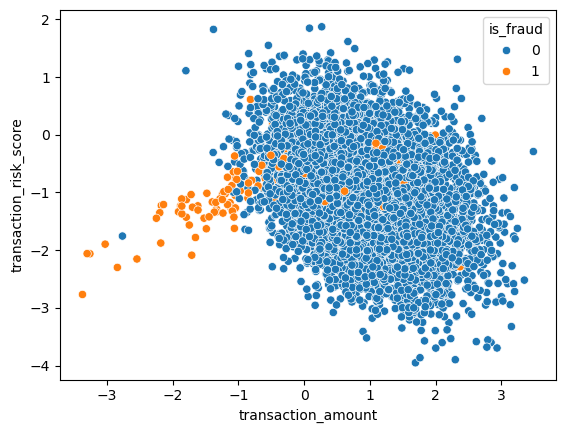

In [13]:
sns.scatterplot(x = X["transaction_amount"],y=X["transaction_risk_score"],hue=y)

In [14]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25,random_state=15)

In [15]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [17]:
penalty = ["l1", "l2", "elasticnet"]
c_values = [100,10,1.0,0.1,0.01]
solver = ["newton-cg","lbfgs","liblinear","sag","saga","newton-cholesky"]
class_weight =[{0:w,1:y} for w in [1,10,50,100] for y in [1,10,50,100]]

In [18]:
class_weight

[{0: 1, 1: 1},
 {0: 1, 1: 10},
 {0: 1, 1: 50},
 {0: 1, 1: 100},
 {0: 10, 1: 1},
 {0: 10, 1: 10},
 {0: 10, 1: 50},
 {0: 10, 1: 100},
 {0: 50, 1: 1},
 {0: 50, 1: 10},
 {0: 50, 1: 50},
 {0: 50, 1: 100},
 {0: 100, 1: 1},
 {0: 100, 1: 10},
 {0: 100, 1: 50},
 {0: 100, 1: 100}]

In [19]:
params = dict(penalty=penalty,C=c_values,solver=solver,class_weight=class_weight)

In [20]:
from sklearn.model_selection import GridSearchCV,StratifiedKFold

In [21]:
cv = StratifiedKFold()

In [22]:
grid = GridSearchCV(estimator=model,param_grid=params,scoring="accuracy",cv=cv)

In [23]:
import warnings
warnings.filterwarnings("ignore")

In [24]:
grid.fit(X_train,y_train)

,estimator,LogisticRegression()
,param_grid,"{'C': [100, 10, ...], 'class_weight': [{0: 1, 1: 1}, {0: 1, 1: 10}, ...], 'penalty': ['l1', 'l2', ...], 'solver': ['newton-cg', 'lbfgs', ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,StratifiedKFo...shuffle=False)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l1'


In [25]:
y_pred = grid.predict(X_test)

In [26]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(2500,))

In [27]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [28]:
print("score",accuracy_score(y_pred,y_test))
print(classification_report(y_pred,y_test))
print("confusion matrix \n",confusion_matrix(y_pred,y_test))

score 0.9876
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      2475
           1       0.42      0.64      0.51        25

    accuracy                           0.99      2500
   macro avg       0.71      0.82      0.75      2500
weighted avg       0.99      0.99      0.99      2500

confusion matrix 
 [[2453   22]
 [   9   16]]


In [29]:
grid.best_params_

{'C': 0.1, 'class_weight': {0: 10, 1: 50}, 'penalty': 'l1', 'solver': 'saga'}

## ROC - AUC
###### The ROC Curve is a graphical representation of a classification model’s performance across different threshold values. It plots the True Positive Rate (Recall) on the Y-axis against the False Positive Rate (1 - Specificity) on the X-axis. • A model that perfectly distinguishes between classes has a curve that reaches the top-left corner. • The closer the curve is to the top-left, the better the model. • The area under the ROC curve (AUC) quantifies this performance: • AUC = 1 → perfect classifier • AUC = 0.5 → random guessingROC is especially useful for imbalanced datasets, as it evaluates the model independent of class distribution or threshold.

In [30]:
model_prob = grid.predict_proba(X_test)

In [31]:
model_prob

array([[9.98721548e-01, 1.27845234e-03],
       [8.55371107e-01, 1.44628893e-01],
       [9.67592073e-01, 3.24079272e-02],
       ...,
       [9.95528857e-01, 4.47114277e-03],
       [9.92452000e-01, 7.54799952e-03],
       [9.99325969e-01, 6.74030801e-04]], shape=(2500, 2))

In [32]:
model_prob = model_prob[:,1] #probabilites for the positive (fraud class)

In [33]:
model_prob

array([0.00127845, 0.14462889, 0.03240793, ..., 0.00447114, 0.007548  ,
       0.00067403], shape=(2500,))

In [34]:
from sklearn.metrics import roc_curve,roc_auc_score

In [35]:
#roc_auc_score:1'e ne kadar yakınsa o kadar iyi calısıyor 0-1 arası
model_auc = roc_auc_score(y_test,model_prob)

In [36]:
model_auc

0.7364359314207534

In [40]:
#x eks. folse positive rate 
# y eks. true positive rate koyuyoruz.
model_fpr,model_tpr,threshold=roc_curve(y_test,model_prob)
#3 dizi veriyor.
#fpr:falve positive rate - true positive rate - threshold(eşikler) veriyor.

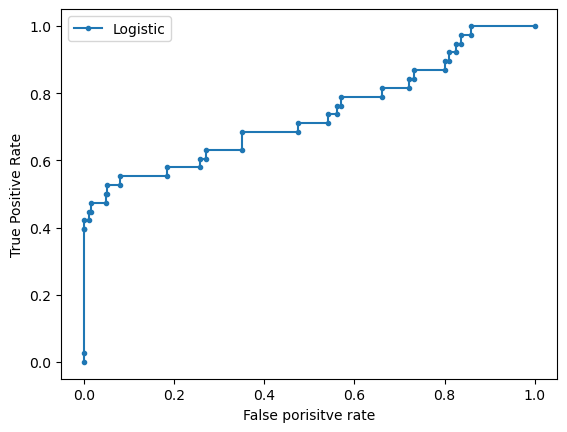

In [41]:
plt.plot(model_fpr,model_tpr,marker=".",label="Logistic")
plt.xlabel("False porisitve rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

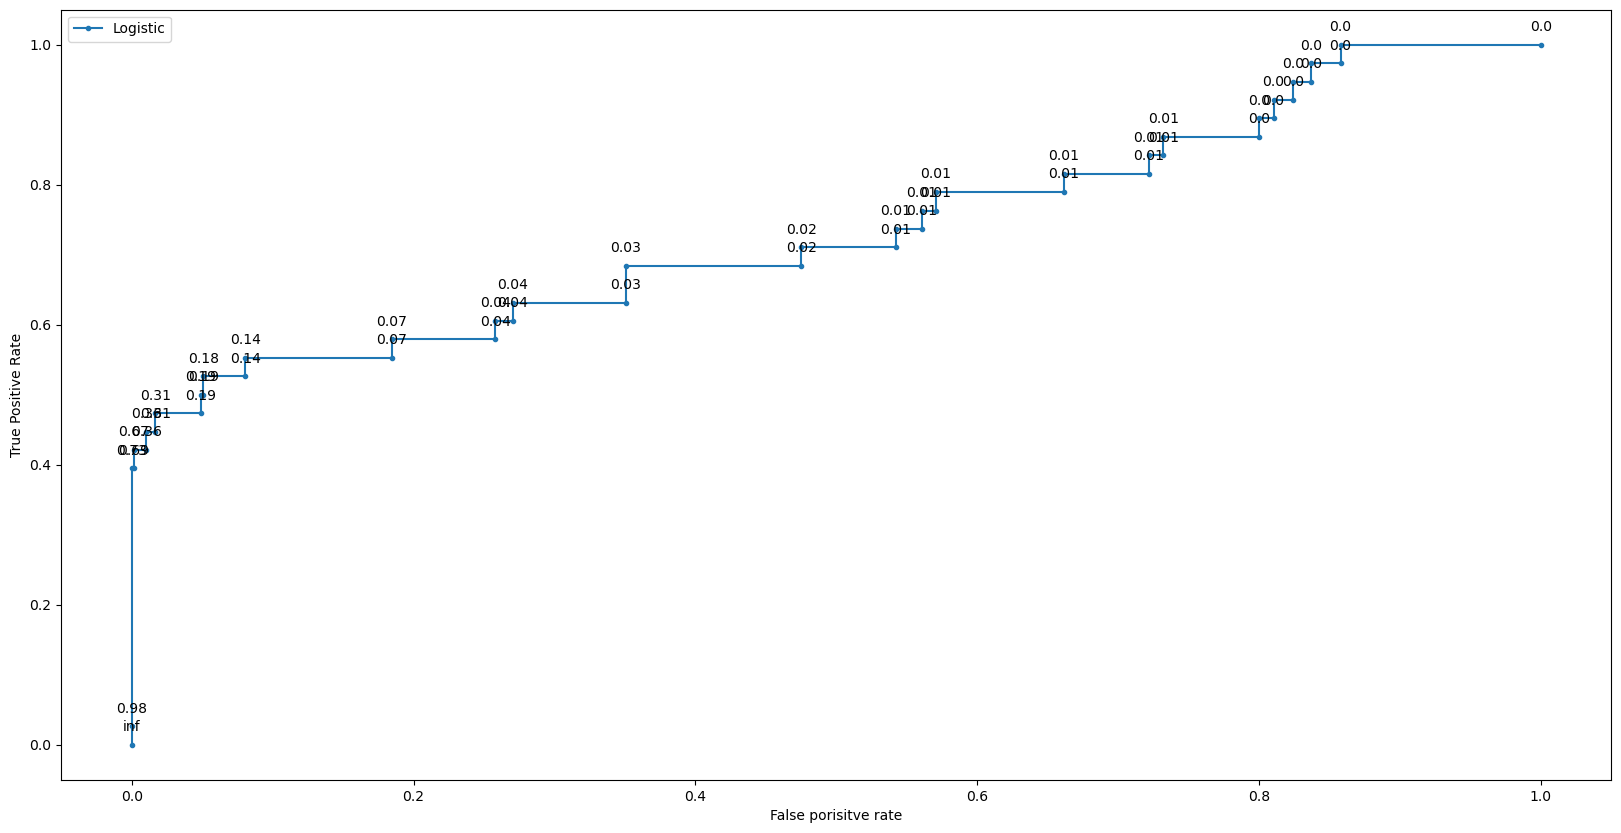

In [43]:
fig,ax = plt.subplots(figsize=(20,10))

ax.plot(model_fpr,model_tpr,marker=".",label="Logistic")

# Annotate each point with the threshold
for fpr, tpr, thresh in zip(model_fpr, model_tpr, threshold):
    ax.annotate(f'{np.round(thresh, 2)}', (fpr, tpr), textcoords="offset points", xytext=(0,10), ha='center')


ax.set_xlabel("False porisitve rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
plt.show()


In [44]:
# Pick a custom threshold (e.g., from your annotated ROC curve)
custom_threshold = 0.2  # You can change this to what you chose

# Predict using custom threshold
y_pred_custom = (model_prob >= custom_threshold).astype(int)
print(model_prob >= custom_threshold)
print(y_pred_custom)

# Evaluate
print(f"\n Evaluation using custom threshold = {custom_threshold}")
print(confusion_matrix(y_test, y_pred_custom))
print(classification_report(y_test, y_pred_custom))

[False False False ... False False False]
[0 0 0 ... 0 0 0]

 Evaluation using custom threshold = 0.2
[[2353  109]
 [  20   18]]
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      2462
           1       0.14      0.47      0.22        38

    accuracy                           0.95      2500
   macro avg       0.57      0.71      0.60      2500
weighted avg       0.98      0.95      0.96      2500



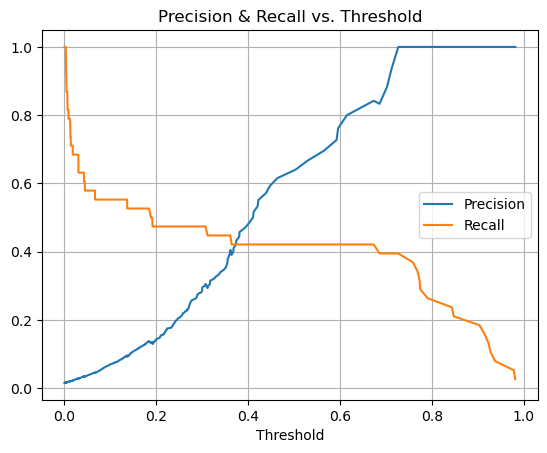

In [45]:
#If you want to find the best threshold based on precision, recall, or F1 you can plot Performance Metrics at Different Thresholds
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, model_prob)

# Plot precision and recall vs threshold
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.xlabel('Threshold')
plt.legend()
plt.title('Precision & Recall vs. Threshold')
plt.grid()
plt.show()